Libraries imported successfully!

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   Species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Statistical Summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species Distribution:


,count
Species,
setosa,50
versicolor,50
virginica,50



Scaled Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,-0.900681,1.019004,-1.340227,-1.315444
1,-1.143017,-0.131979,-1.340227,-1.315444
2,-1.385353,0.328414,-1.397064,-1.315444
3,-1.506521,0.098217,-1.283389,-1.315444
4,-1.021849,1.249201,-1.340227,-1.315444


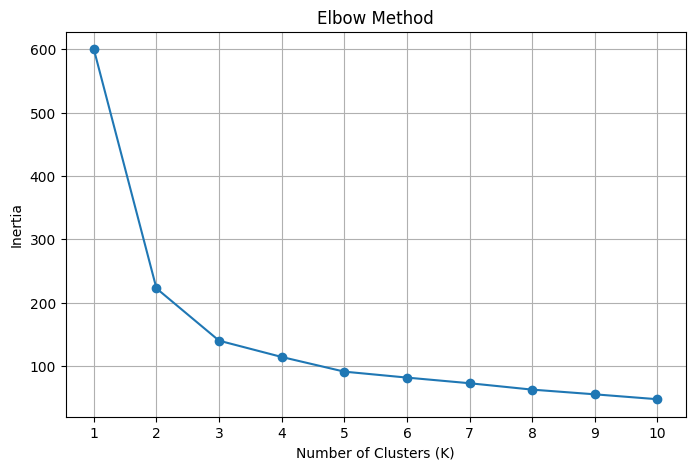


Clustered Dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species,Predicted Cluster
0,5.1,3.5,1.4,0.2,setosa,1
1,4.9,3.0,1.4,0.2,setosa,1
2,4.7,3.2,1.3,0.2,setosa,1
3,4.6,3.1,1.5,0.2,setosa,1
4,5.0,3.6,1.4,0.2,setosa,1
5,5.4,3.9,1.7,0.4,setosa,1
6,4.6,3.4,1.4,0.3,setosa,1
7,5.0,3.4,1.5,0.2,setosa,1
8,4.4,2.9,1.4,0.2,setosa,1
9,4.9,3.1,1.5,0.1,setosa,1



Cluster Distribution:
Predicted Cluster
0    53
1    50
2    47
Name: count, dtype: int64

Silhouette Score: 0.4599


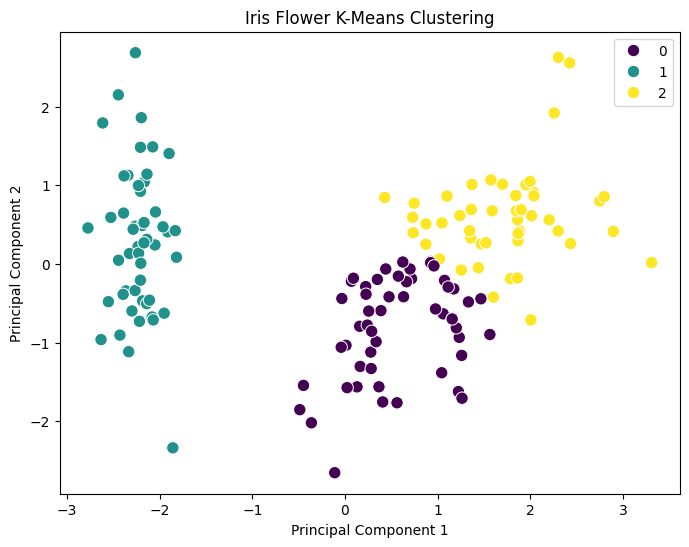


Original Dimensions: (150, 4)
Reduced Dimensions: (150, 2)

Explained Variance Ratio:
[0.72962445 0.22850762]

Total Variance Retained: 95.81 %


,PC1,PC2
0,-2.264703,0.480027
1,-2.080961,-0.674134
2,-2.364229,-0.341908
3,-2.299384,-0.597395
4,-2.389842,0.646835


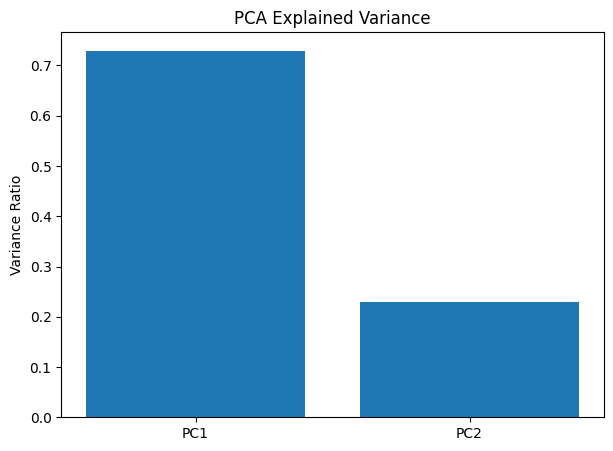


Actual Species vs Predicted Clusters:


Predicted Cluster,0,1,2
Actual Species,,,
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36



Adjusted Rand Index: 0.6201


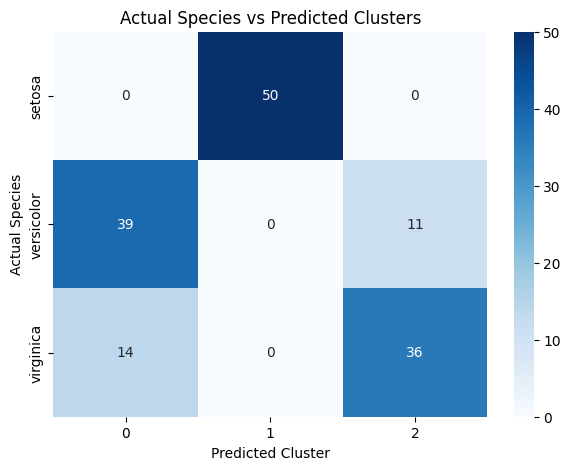


Model saved successfully using Joblib!
Joblib predictions match: True

Model saved successfully using Pickle!
Pickle predictions match: True

All CSV files exported successfully!

WEEK 3 ASSIGNMENT COMPLETED!

Generated Files:
outputs/iris_cluster_assignments.csv
outputs/iris_pca_results.csv
outputs/iris_species_cluster_comparison.csv
models/iris_kmeans_joblib.pkl
models/iris_kmeans_pickle.pkl
visualizations/cluster_comparison.png
visualizations/elbow_method.png
visualizations/kmeans_clusters.png
visualizations/pca_variance.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# WEEK 3 - UNSUPERVISED LEARNING + MODEL EVALUATION
# MINI PROJECT: IRIS FLOWER CLUSTERING
# ============================================================

# 1. INSTALL AND IMPORT LIBRARIES

%pip install -q numpy pandas matplotlib seaborn scikit-learn joblib

import os
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.pipeline import Pipeline

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)
os.makedirs("visualizations", exist_ok=True)

print("Libraries imported successfully!")


# ============================================================
# 2. LOAD IRIS DATASET
# ============================================================

iris = load_iris(as_frame=True)

X = iris.data
y_true = iris.target

iris_df = X.copy()
iris_df["Species"] = [
    iris.target_names[i] for i in y_true
]

print("\nFirst five rows:")
display(iris_df.head())

print("\nDataset Information:")
iris_df.info()

print("\nStatistical Summary:")
display(X.describe())

print("\nSpecies Distribution:")
display(iris_df["Species"].value_counts())


# ============================================================
# 3. FEATURE SCALING
# ============================================================

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print("\nScaled Dataset:")
display(scaled_df.head())


# ============================================================
# 4. ELBOW METHOD TO FIND OPTIMAL K
# ============================================================

inertia_values = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    inertia_values.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    inertia_values,
    marker="o"
)

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(1, 11))
plt.grid()

plt.savefig(
    "visualizations/elbow_method.png",
    dpi=150
)

plt.show()


# ============================================================
# 5. APPLY K-MEANS CLUSTERING (K=3)
# ============================================================

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

clustered_df = iris_df.copy()

clustered_df["Predicted Cluster"] = cluster_labels

print("\nClustered Dataset:")
display(clustered_df.head(10))

print("\nCluster Distribution:")
print(clustered_df["Predicted Cluster"].value_counts())

silhouette = silhouette_score(
    X_scaled,
    cluster_labels
)

print("\nSilhouette Score:", round(silhouette, 4))


# ============================================================
# 6. VISUALIZE K-MEANS CLUSTERS USING SCATTER PLOT
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=cluster_labels,
    palette="viridis",
    s=80
)

plt.title("Iris Flower K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.savefig(
    "visualizations/kmeans_clusters.png",
    dpi=150
)

plt.show()


# ============================================================
# 7. PCA - PRINCIPAL COMPONENT ANALYSIS
# ============================================================

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

print("\nOriginal Dimensions:", X_scaled.shape)
print("Reduced Dimensions:", X_pca.shape)

print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

print(
    "\nTotal Variance Retained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

display(pca_df.head())


# PCA Explained Variance Visualization

plt.figure(figsize=(7, 5))

plt.bar(
    ["PC1", "PC2"],
    pca.explained_variance_ratio_
)

plt.title("PCA Explained Variance")
plt.ylabel("Variance Ratio")

plt.savefig(
    "visualizations/pca_variance.png",
    dpi=150
)

plt.show()


# ============================================================
# 8. COMPARE PREDICTED CLUSTERS WITH TRUE LABELS
# ============================================================

comparison = pd.DataFrame({
    "Actual Species": [
        iris.target_names[i] for i in y_true
    ],
    "Predicted Cluster": cluster_labels
})

print("\nActual Species vs Predicted Clusters:")

comparison_table = pd.crosstab(
    comparison["Actual Species"],
    comparison["Predicted Cluster"]
)

display(comparison_table)


# Adjusted Rand Index

ari = adjusted_rand_score(
    y_true,
    cluster_labels
)

print("\nAdjusted Rand Index:", round(ari, 4))


# Confusion-style comparison heatmap

plt.figure(figsize=(7, 5))

sns.heatmap(
    comparison_table,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Actual Species vs Predicted Clusters")
plt.xlabel("Predicted Cluster")
plt.ylabel("Actual Species")

plt.savefig(
    "visualizations/cluster_comparison.png",
    dpi=150
)

plt.show()


# ============================================================
# 9. SAVE MODEL USING JOBLIB
# ============================================================

clustering_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("kmeans", KMeans(
        n_clusters=3,
        random_state=42,
        n_init=10
    ))
])

clustering_pipeline.fit(X)

joblib.dump(
    clustering_pipeline,
    "models/iris_kmeans_joblib.pkl"
)

print("\nModel saved successfully using Joblib!")


# Load model using Joblib

loaded_joblib_model = joblib.load(
    "models/iris_kmeans_joblib.pkl"
)

joblib_predictions = loaded_joblib_model.predict(X)

print(
    "Joblib predictions match:",
    np.array_equal(cluster_labels, joblib_predictions)
)


# ============================================================
# 10. SAVE MODEL USING PICKLE
# ============================================================

with open(
    "models/iris_kmeans_pickle.pkl",
    "wb"
) as file:

    pickle.dump(clustering_pipeline, file)

print("\nModel saved successfully using Pickle!")


# Load model using Pickle

with open(
    "models/iris_kmeans_pickle.pkl",
    "rb"
) as file:

    loaded_pickle_model = pickle.load(file)

pickle_predictions = loaded_pickle_model.predict(X)

print(
    "Pickle predictions match:",
    np.array_equal(cluster_labels, pickle_predictions)
)


# ============================================================
# 11. EXPORT RESULTS
# ============================================================

clustered_df.to_csv(
    "outputs/iris_cluster_assignments.csv",
    index=False
)

comparison_table.to_csv(
    "outputs/iris_species_cluster_comparison.csv"
)

pca_df.to_csv(
    "outputs/iris_pca_results.csv",
    index=False
)

print("\nAll CSV files exported successfully!")


# ============================================================
# 12. CREATE ZIP FILE OF ALL OUTPUTS
# ============================================================

import zipfile

with zipfile.ZipFile(
    "Week3_Iris_Clustering_Results.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for folder in ["outputs", "models", "visualizations"]:

        for root, dirs, files_list in os.walk(folder):

            for filename in files_list:

                file_path = os.path.join(
                    root,
                    filename
                )

                zip_file.write(file_path)


print("\n===================================")
print("WEEK 3 ASSIGNMENT COMPLETED!")
print("===================================")

print("\nGenerated Files:")

for folder in ["outputs", "models", "visualizations"]:

    for filename in sorted(os.listdir(folder)):

        print(os.path.join(folder, filename))


# Download ZIP in Google Colab

from google.colab import files

files.download("Week3_Iris_Clustering_Results.zip")
